[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-1/blob/main/notebooks/ch10_LabCh10_Normalization_Layers.ipynb)

**The Why Book of Deep Learning, Part 1** by Dr. Philemon Paul Daniel

**Chapter 10: Normalization Layers** (Part II: Making It Learn).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-1/read.html?ch=10](https://www.micyaai.com/books/why-deep-learning-1/read.html?ch=10)
* The video course this book grew from: [www.aikids.guru](https://www.aikids.guru)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)

Tested with TensorFlow 2.21 and Keras 3.14. In Colab: *Runtime > Run all*. A GPU runtime makes the bigger
models faster but none of them needs one.

---


# Lab Ch10 - Normalization Layers
## BatchNorm by hand, its two personalities, and what it buys a real CNN

This lab goes with **Chapter 10** of *The Why Book of Deep Learning*.

A `BatchNormalization` layer is four lines of arithmetic and two running averages. Most of the trouble
people have with it comes from not knowing which of those it is using at a given moment. In this lab
you compute it yourself, catch Keras doing exactly the same sums, and then watch what it does to training.

### What you will be able to do afterwards

| Skill | Where |
|---|---|
| Compute BatchNorm by hand and check it against Keras | Steps 2 to 4 |
| Say what `gamma` and `beta` are for, and prove they can undo the normalisation | Step 5 |
| Explain training mode vs inference mode, and the moving averages | Steps 6 to 9 |
| Count trainable and non-trainable parameters by hand | Steps 10 and 11 |
| Say exactly what `trainable = False` does to a BatchNormalization layer | Step 12 |
| Compare a CNN with and without BatchNorm at a normal and a high learning rate | Steps 13 to 17 |
| Use LayerNormalization and GroupNormalization, and see BatchNorm fail at batch size 2 | Steps 18 to 23 |

### The rule of this lab: predict, then run

Every step asks you to **write down a prediction before you run the cell**.

> **Runtime:** a laptop CPU is enough: about four minutes plus the time to import TensorFlow.
> To keep it that fast we train on **10,000** Fashion-MNIST images, validate on 2,000 others, and run
> only 6 epochs. For a real run use all 60,000 images and 20 or more epochs: the gaps between the
> runs get smaller in percentage points but keep the same order.

---
# Part A - BatchNorm by hand

---
## Step 1 - Imports and one seed

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)
np.set_printoptions(precision=3, suppress=True)

print("TensorFlow:", tf.__version__)
print("Keras     :", keras.__version__)

TensorFlow: 2.21.0
Keras     : 3.14.1


---
## Step 2 - A tiny batch with badly scaled features

Four examples, three features on wildly different scales, as you would meet them in a hidden layer
whose units have drifted apart: one around 170, one around 0.5, one around -40.

> **Predict:** the mean of each column (do it in your head, roughly).

In [2]:
x = np.array([[170.0, 0.2, -38.0],
              [182.0, 0.9, -45.0],
              [158.0, 0.4, -41.0],
              [174.0, 0.5, -36.0]], dtype="float32")
print("batch shape:", x.shape, "  (4 examples, 3 features)")
print("column means:", x.mean(axis=0))
print("column stds :", x.std(axis=0))

batch shape: (4, 3)   (4 examples, 3 features)
column means: [171.    0.5 -40. ]
column stds : [8.66  0.255 3.391]


---
## Step 3 - The four moves, in NumPy

For **each feature (column) separately**, across the batch:

1. subtract the batch mean,
2. divide by the batch standard deviation (with a tiny `epsilon` inside the square root so we never divide by zero),
3. multiply by a learnt scale `gamma`,
4. add a learnt shift `beta`.

A fresh layer starts with `gamma = 1` and `beta = 0`, so moves 3 and 4 do nothing yet.
Keras uses `epsilon = 0.001` and the **biased** variance (divide by n, not n - 1).

> **Predict:** the mean and standard deviation of every column of the result.

In [3]:
EPS = 1e-3
mu = x.mean(axis=0)
var = x.var(axis=0)                  # biased: divides by n
x_hat = (x - mu) / np.sqrt(var + EPS)
gamma, beta = np.ones(3, "float32"), np.zeros(3, "float32")
y_hand = gamma * x_hat + beta

print("normalised batch:\n", y_hand)
print("column means:", y_hand.mean(axis=0).round(6))
print("column stds :", y_hand.std(axis=0))

normalised batch:
 [[-0.115 -1.168  0.59 ]
 [ 1.27   1.557 -1.474]
 [-1.501 -0.389 -0.295]
 [ 0.346  0.     1.179]]
column means: [-0. -0.  0.]
column stds : [1.    0.992 1.   ]


### Why we see this

Every column now has mean 0 and standard deviation 1 (very slightly below 1 in the middle column,
whose variance is so small that the 0.001 of epsilon is no longer negligible). The 170s, the 0.5s
and the -40s have become numbers of the same size. The **order inside each column is untouched**:
the tallest example is still the largest number. Normalisation changes the ruler, not the ranking.

---
## Step 4 - Catch Keras doing the same sums

Call a `BatchNormalization` layer on the same batch with `training=True` (the mode `fit` uses).

> **Predict:** the largest difference between Keras and our NumPy result.

In [4]:
bn = layers.BatchNormalization()
print("Keras defaults: momentum =", bn.momentum, " epsilon =", bn.epsilon)
y_keras = bn(x, training=True).numpy()
print("Keras output:\n", y_keras)
print("largest difference from NumPy:", np.abs(y_keras - y_hand).max())
assert np.allclose(y_keras, y_hand, atol=1e-4)

Keras defaults: momentum = 0.99  epsilon = 0.001
Keras output:
 [[-0.115 -1.168  0.59 ]
 [ 1.27   1.557 -1.474]
 [-1.501 -0.389 -0.295]
 [ 0.346  0.     1.179]]
largest difference from NumPy: 9.834766e-07


---
## Step 5 - Why give the scale back?

If normalising is good, why does the layer then learn `gamma` and `beta`, which can scale and shift
everything again? Because the best range for the next layer might **not** be mean 0, std 1. With the
two knobs the layer can choose any mean and spread, including the original ones.

> **Predict:** if we set `gamma` to the batch std and `beta` to the batch mean, what comes out?

In [5]:
gamma_undo = np.sqrt(var + EPS)
beta_undo = mu
bn.set_weights([gamma_undo, beta_undo, bn.moving_mean.numpy(), bn.moving_variance.numpy()])
y_undo = bn(x, training=True).numpy()
print("output with gamma = std, beta = mean:\n", y_undo)
print("largest difference from the raw input:", np.abs(y_undo - x).max())
assert np.allclose(y_undo, x, atol=1e-3)

output with gamma = std, beta = mean:
 [[170.    0.2 -38. ]
 [182.    0.9 -45. ]
 [158.    0.4 -41. ]
 [174.    0.5 -36. ]]
largest difference from the raw input: 0.0


### Why we see this

The layer handed back its own input. So adding BatchNorm can never make a network *less* able to
represent something: in the worst case it learns to undo itself. What changes is how easy the
landscape is to walk on, not what the network can express.

---
# Part B - Two personalities: training and inference

---
## Step 6 - Look inside a fresh layer

> **Predict:** how many weight arrays does a BatchNormalization layer on 3 features hold, and how many
> of them does the optimiser train?

In [6]:
bn = layers.BatchNormalization()
bn.build((None, 3))
for w in bn.weights:
    print(f"{w.name:16s} shape {tuple(w.shape)}  trainable={w.trainable}  value {w.numpy()}")

gamma            shape (3,)  trainable=True  value [1. 1. 1.]
beta             shape (3,)  trainable=True  value [0. 0. 0.]
moving_mean      shape (3,)  trainable=False  value [0. 0. 0.]
moving_variance  shape (3,)  trainable=False  value [1. 1. 1.]


### Why we see this

Four arrays, one number per feature in each: `gamma` and `beta` are learnt by gradient descent;
`moving_mean` and `moving_variance` are **not** trained at all. They are bookkeeping: running averages
of the batch statistics, kept for the day the layer has no batch to look at.

---
## Step 7 - One training call nudges the moving averages

Keras updates `moving = momentum * moving + (1 - momentum) * batch_stat` with `momentum = 0.99`.
The moving mean starts at 0.

> **Predict:** the moving mean after ONE training call on our batch (column means 171, 0.5, -40).

In [7]:
_ = bn(x, training=True)
print("batch mean       :", mu)
print("moving mean now  :", bn.moving_mean.numpy())
print("0.01 x batch mean:", 0.01 * mu)
assert np.allclose(bn.moving_mean.numpy(), 0.01 * mu, atol=1e-4)

batch mean       : [171.    0.5 -40. ]
moving mean now  : [ 1.71   0.005 -0.4  ]
0.01 x batch mean: [ 1.71   0.005 -0.4  ]


---
## Step 8 - Inference mode uses the moving averages

`training=False` (what `predict` and `evaluate` use) normalises with the **moving** mean and variance,
not the batch's own.

> **Predict:** after only one training call, does inference mode normalise our batch properly?

In [8]:
y_train_mode = bn(x, training=True).numpy()
y_infer_mode = bn(x, training=False).numpy()
print("training mode (batch stats):\n", y_train_mode)
print("inference mode (moving stats):\n", y_infer_mode)

training mode (batch stats):
 [[-0.115 -1.168  0.59 ]
 [ 1.27   1.557 -1.474]
 [-1.501 -0.389 -0.295]
 [ 0.346  0.     1.179]]
inference mode (moving stats):
 [[105.926   0.192 -33.823]
 [113.556   0.898 -40.186]
 [ 98.296   0.394 -36.55 ]
 [108.469   0.494 -32.004]]


### Why we see this

Inference mode subtracts a moving mean that is only about 2% of the way to the truth (two training calls
so far) and divides by a moving variance that is still close to its starting value of 1. So it barely
normalises: the 170s come out above 100 instead of near 0. The averages need many steps to catch up.
Step 9 counts how many.

---
## Step 9 - How fast do the moving averages catch up?

Feed the layer 500 batches drawn from data whose true mean is 5 and true std is 2.

> **Predict:** after how many steps is the moving mean within 1% of 5, with momentum 0.99? With 0.9?

momentum 0.99: after  10 steps moving mean = 0.474   (theory 5 x (1 - 0.99^10) = 0.478)
momentum 0.99: after  50 steps moving mean = 1.952   (theory 5 x (1 - 0.99^50) = 1.975)
momentum 0.99: after 100 steps moving mean = 3.176   (theory 5 x (1 - 0.99^100) = 3.170)
momentum 0.99: after 300 steps moving mean = 4.779   (theory 5 x (1 - 0.99^300) = 4.755)
momentum 0.99: after 500 steps moving mean = 4.962   (theory 5 x (1 - 0.99^500) = 4.967)



momentum 0.9: after  10 steps moving mean = 3.285   (theory 5 x (1 - 0.9^10) = 3.257)
momentum 0.9: after  50 steps moving mean = 5.044   (theory 5 x (1 - 0.9^50) = 4.974)
momentum 0.9: after 100 steps moving mean = 4.999   (theory 5 x (1 - 0.9^100) = 5.000)
momentum 0.9: after 300 steps moving mean = 4.940   (theory 5 x (1 - 0.9^300) = 5.000)
momentum 0.9: after 500 steps moving mean = 5.146   (theory 5 x (1 - 0.9^500) = 5.000)



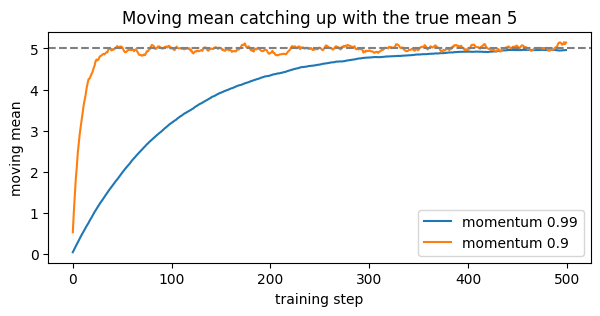

steps until the starting value weighs under 1%: 459 (0.99) and 44 (0.9)


In [9]:
rng = np.random.default_rng(0)
history = {}
for mom in (0.99, 0.9):
    layer = layers.BatchNormalization(momentum=mom)
    layer.build((None, 1))
    trace = []
    for step in range(500):
        batch = rng.normal(5.0, 2.0, size=(64, 1)).astype("float32")
        layer(batch, training=True)
        trace.append(float(layer.moving_mean.numpy()[0]))
    history[mom] = np.array(trace)
    for n in (10, 50, 100, 300, 500):
        print(f"momentum {mom}: after {n:3d} steps moving mean = {trace[n-1]:.3f}   "
              f"(theory 5 x (1 - {mom}^{n}) = {5 * (1 - mom**n):.3f})")
    print()

plt.figure(figsize=(7, 3))
for mom, tr in history.items():
    plt.plot(tr, label=f"momentum {mom}")
plt.axhline(5, color="grey", ls="--")
plt.xlabel("training step"); plt.ylabel("moving mean"); plt.legend(); plt.title("Moving mean catching up with the true mean 5")
plt.show()

steps_99 = int(np.ceil(np.log(0.01) / np.log(0.99)))
steps_90 = int(np.ceil(np.log(0.01) / np.log(0.9)))
print("steps until the starting value weighs under 1%:", steps_99, "(0.99) and", steps_90, "(0.9)")

### Why we see this

The starting value (0) keeps a weight of `momentum^n` after n steps. With 0.99 that drops below 1% only after
**459** steps; with 0.9 after **44**. A run of 10,000 images at batch size 128 is 79 steps per epoch,
so with the Keras default the inference-mode statistics are still dragging their starting values
through the first several epochs. Remember this in Step 16.

(PyTorch writes the same idea the other way round: its `momentum=0.1` is the weight of the *new*
value, which is Keras `momentum=0.9`.)

---
## Step 10 - In training mode, your answer depends on your batch-mates

Take one fixed example and normalise it in two different batches.

> **Predict:** is its output the same in both batches? In inference mode?

In [10]:
probe = np.array([[175.0, 0.5, -40.0]], dtype="float32")
batch_a = np.vstack([probe, x[:3]])
batch_b = np.vstack([probe, x[:3] + np.array([30.0, 1.0, 10.0], dtype="float32")])
print("training mode,  batch A:", bn(batch_a, training=True).numpy()[0])
print("training mode,  batch B:", bn(batch_b, training=True).numpy()[0])
print("inference mode, batch A:", bn(batch_a, training=False).numpy()[0])
print("inference mode, batch B:", bn(batch_b, training=False).numpy()[0])

training mode,  batch A: [0.428 0.    0.392]
training mode,  batch B: [-1.363 -1.49  -1.444]
inference mode, batch A: [ 74.585   0.481 -31.925]
inference mode, batch B: [ 74.585   0.481 -31.925]


### Why we see this

In training mode the same example gets a different output because the *other* examples changed the
batch mean. That is the source of BatchNorm's mild regularising noise, and the reason it must switch to
fixed statistics at inference: a prediction for one customer must not depend on who else happened to
be in the request.

---
# Part C - Counting the parameters

---
## Step 11 - Conv2D(32) followed by BatchNormalization

Conv → BN → ReLU is the standard order. The conv's bias is dropped (`use_bias=False`) because BN's
`beta` does the same job (Step 12 shows why).

> **Predict by hand:** the conv's parameters (3 x 3 x 1 weights per filter, 32 filters, no bias), the BN
> layer's parameters (4 per channel), and how many of them are non-trainable.

In [11]:
small = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
])
small.summary()

conv_hand = 3 * 3 * 1 * 32
bn_hand = 4 * 32
trainable_hand = conv_hand + 2 * 32
non_trainable_hand = 2 * 32
n_tr = sum(int(np.prod(w.shape)) for w in small.trainable_weights)
n_nt = sum(int(np.prod(w.shape)) for w in small.non_trainable_weights)
print("by hand : conv", conv_hand, "+ BN", bn_hand, "=", conv_hand + bn_hand,
      "| trainable", trainable_hand, "| non-trainable", non_trainable_hand)
print("by Keras: total", small.count_params(), "| trainable", n_tr, "| non-trainable", n_nt)
assert small.count_params() == conv_hand + bn_hand == 416
assert (n_tr, n_nt) == (352, 64)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 26, 26, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 26, 26, 32)     │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 416 (1.62 KB)

 Trainable params: 352 (1.38 KB)

 Non-trainable params: 64 (256.00 B)

by hand : conv 288 + BN 128 = 416 | trainable 352 | non-trainable 64
by Keras: total 416 | trainable 352 | non-trainable 64


### Why we see this

128 BatchNorm parameters on 32 channels: 32 `gamma`, 32 `beta`, 32 moving means, 32 moving variances.
Only the first 64 are trained. The other 64 are why `model.summary()` suddenly prints a
"Non-trainable params" line the moment BatchNorm appears. Notice that BN's count depends only on the
number of channels, not on the 26 x 26 positions: one mean and one variance per channel, shared by every pixel.

---
## Step 12 - Why the conv bias is redundant

A bias adds the same constant to every value of a channel. BatchNorm subtracts the channel's mean.

> **Predict:** what happens to BN's training-mode output if we add 7 to every input value?

In [12]:
bn_test = layers.BatchNormalization()
out1 = bn_test(x, training=True).numpy()
out2 = bn_test(x + 7.0, training=True).numpy()
print("largest change after adding 7:", np.abs(out1 - out2).max())
assert np.allclose(out1, out2, atol=1e-3)

largest change after adding 7: 1.9073486e-06


The constant vanishes in the subtraction, so a bias before BN is a parameter that can never matter.
`beta` after the normalisation is the shift that survives.

---
## Step 13 - What does `trainable = False` do to a BatchNormalization layer?

This matters when you freeze a pretrained backbone. There are two separate questions:
are `gamma` and `beta` updated, and are the moving averages updated (and used)?

> **Predict:** with `trainable = False`, called with `training=True` and inside `fit`: does the output use
> batch statistics or moving statistics? Do the moving averages change?

In [13]:
frozen = layers.BatchNormalization()
frozen.build((None, 3))
frozen.trainable = False
mm_before = frozen.moving_mean.numpy().copy()
out = frozen(x, training=True).numpy()
uses_moving = np.allclose(out, (x - mm_before) / np.sqrt(frozen.moving_variance.numpy() + EPS), atol=1e-4)
print("called with training=True: uses moving statistics?", uses_moving,
      "| moving mean changed?", not np.allclose(mm_before, frozen.moving_mean.numpy()))

inp = layers.Input(shape=(3,))
mid = layers.BatchNormalization(name="bn")(inp)
outp = layers.Dense(1)(mid)
m = keras.Model(inp, outp)
m.get_layer("bn").trainable = False
m.compile(optimizer="sgd", loss="mse")
before = [w.numpy().copy() for w in m.get_layer("bn").weights]
m.fit(x, np.ones((4, 1)), epochs=3, verbose=0)
after = [w.numpy() for w in m.get_layer("bn").weights]
for w, b, a in zip(m.get_layer("bn").weights, before, after):
    print(f"inside fit: {w.name:16s} changed? {not np.allclose(b, a)}")
assert uses_moving and all(np.allclose(b, a) for b, a in zip(before, after))

called with training=True: uses moving statistics? True | moving mean changed? False


inside fit: gamma            changed? False
inside fit: beta             changed? False
inside fit: moving_mean      changed? False
inside fit: moving_variance  changed? False


### Why we see this

In Keras 3, setting `trainable = False` on a BatchNormalization layer does **two** things: its `gamma` and
`beta` stop learning, **and** the layer runs in inference mode (moving statistics, no updates) even when
`fit` passes `training=True`. That is the behaviour you want when fine-tuning a pretrained network on a
small dataset: the backbone's statistics, learnt on millions of images, are not overwritten by a few
noisy batches of yours. (This is a Keras-specific rule; other libraries separate the two switches.)

---
# Part D - The race: with and without BatchNorm

---
## Step 14 - Load a slice of Fashion-MNIST

In [14]:
(x_all, y_all), _ = keras.datasets.fashion_mnist.load_data()
N_TRAIN, N_VAL = 10_000, 2_000
x_train = x_all[:N_TRAIN, ..., np.newaxis].astype("float32") / 255.0
y_train = y_all[:N_TRAIN]
x_val = x_all[50_000:50_000 + N_VAL, ..., np.newaxis].astype("float32") / 255.0
y_val = y_all[50_000:50_000 + N_VAL]
print("x_train:", x_train.shape, " x_val:", x_val.shape)

x_train: (10000, 28, 28, 1)  x_val: (2000, 28, 28, 1)


---
## Step 15 - Two CNNs that differ only in BatchNorm

Four `3 x 3` convolutions with `'same'` padding (32, 32, 64, 64 filters), a pool after every second one,
global average pooling and a `Dense(10)` softmax. The BN version puts Conv (no bias) → BN → ReLU in each block.
The BN momentum is set to **0.9** because this is a short run (Step 9 said why; Step 17 shows it).

> **Predict by hand** both parameter counts, and the BN model's non-trainable count.

In [15]:
def build_cnn(norm=None, momentum=0.9):
    """norm: None, 'bn' (BatchNormalization) or 'ln' (GroupNormalization with one group = LayerNorm over H, W, C)."""
    model = [layers.Input(shape=(28, 28, 1))]
    for i, f in enumerate([32, 32, 64, 64]):
        if norm is None:
            model.append(layers.Conv2D(f, (3, 3), padding="same", activation="relu"))
        else:
            model.append(layers.Conv2D(f, (3, 3), padding="same", use_bias=False))
            model.append(layers.BatchNormalization(momentum=momentum) if norm == "bn" else layers.GroupNormalization(groups=1))
            model.append(layers.Activation("relu"))
        if i % 2 == 1:
            model.append(layers.MaxPooling2D((2, 2)))
    model += [layers.GlobalAveragePooling2D(), layers.Dense(10, activation="softmax")]
    return keras.Sequential(model)

plain_hand = (9*1 + 1)*32 + (9*32 + 1)*32 + (9*32 + 1)*64 + (9*64 + 1)*64 + (64*10 + 10)
conv_nobias = 9*1*32 + 9*32*32 + 9*32*64 + 9*64*64
bn_params = 4 * (32 + 32 + 64 + 64)
bn_hand = conv_nobias + bn_params + (64*10 + 10)
nontrain_hand = 2 * (32 + 32 + 64 + 64)

plain_model, bn_model = build_cnn(None), build_cnn("bn")
bn_nt = sum(int(np.prod(w.shape)) for w in bn_model.non_trainable_weights)
print("plain CNN: by hand", plain_hand, " Keras", plain_model.count_params())
print("BN CNN   : by hand", bn_hand, " Keras", bn_model.count_params(), " non-trainable", bn_nt)
assert plain_model.count_params() == plain_hand == 65_642
assert bn_model.count_params() == bn_hand == 66_218 and bn_nt == nontrain_hand == 384

plain CNN: by hand 65642  Keras 65642
BN CNN   : by hand 66218  Keras 66218  non-trainable 384


---
## Step 16 - Train four runs: {plain, BN} x {normal, high} learning rate

SGD with momentum 0.9, batch size 128, 6 epochs. "Normal" is 0.01; "high" is 0.5, fifty times larger.
Every run starts from the same seed.

> **Predict before running:** which of the four runs fail to learn at all? Which is best after 6 epochs?
> (This cell takes about two minutes.)

In [16]:
def train(norm, lr, momentum=0.9, epochs=6, batch_size=128, xs=x_train, ys=y_train):
    keras.utils.set_random_seed(0)
    model = build_cnn(norm, momentum)
    model.compile(optimizer=keras.optimizers.SGD(lr, momentum=0.9),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    t = time.time()
    h = model.fit(xs, ys, batch_size=batch_size, epochs=epochs, validation_data=(x_val, y_val), verbose=0)
    return model, h.history, time.time() - t

runs = {}
for lr in (0.01, 0.5):
    for norm in (None, "bn"):
        name = f"{'BN' if norm else 'plain'} lr={lr}"
        _, runs[name], secs = train(norm, lr)
        print(f"{name:14s} train loss {np.round(runs[name]['loss'], 3)}  "
              f"val acc {np.round(runs[name]['val_accuracy'], 3)}  ({secs:.0f}s)")

plain lr=0.01  train loss [2.28  2.135 1.566 1.153 0.929 0.828]  val acc [0.112 0.397 0.387 0.663 0.625 0.662]  (28s)


BN lr=0.01     train loss [1.323 0.755 0.617 0.542 0.492 0.456]  val acc [0.708 0.714 0.773 0.732 0.785 0.789]  (70s)


plain lr=0.5   train loss [2.323 2.313 2.314 2.314 2.314 2.314]  val acc [0.097 0.097 0.097 0.097 0.097 0.097]  (27s)


BN lr=0.5      train loss [1.087 0.697 0.554 0.475 0.418 0.395]  val acc [0.466 0.692 0.746 0.775 0.837 0.826]  (67s)


---
## Step 17 - Plot the curves

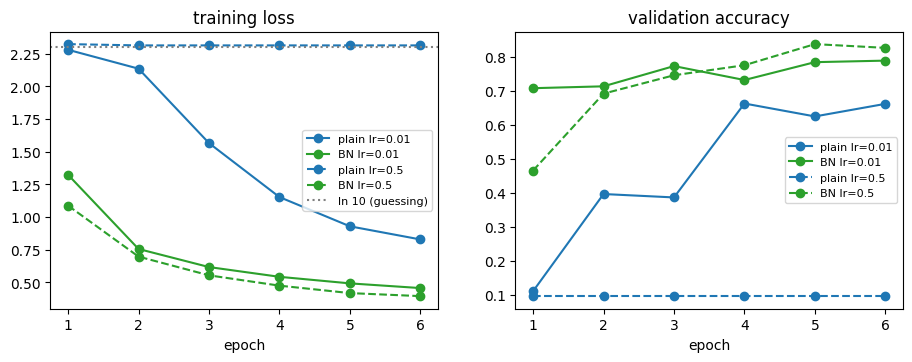

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
styles = {"plain lr=0.01": ("tab:blue", "-"), "BN lr=0.01": ("tab:green", "-"),
          "plain lr=0.5": ("tab:blue", "--"), "BN lr=0.5": ("tab:green", "--")}
for name, h in runs.items():
    c, ls = styles[name]
    ax[0].plot(range(1, 7), h["loss"], color=c, ls=ls, marker="o", label=name)
    ax[1].plot(range(1, 7), h["val_accuracy"], color=c, ls=ls, marker="o", label=name)
ax[0].axhline(np.log(10), color="grey", ls=":", label="ln 10 (guessing)")
ax[0].set_title("training loss"); ax[1].set_title("validation accuracy")
for a in ax:
    a.set_xlabel("epoch"); a.legend(fontsize=8)
plt.show()

### Why we see this

* At **lr = 0.01** both learn, but the BN network gets to a given training loss in far fewer epochs.
  Without BN the plain net spends its first epoch or two almost at the guessing loss of ln 10 = 2.303.
* At **lr = 0.5** the plain network is destroyed in the first epoch: its loss sits at about 2.31,
  the loss of a model that outputs the same probabilities for everything, and stays there. The BN network
  trains happily at fifty times the learning rate. This is the most useful thing BatchNorm buys:
  a wide range of learning rates that work.
* The BN curves of validation accuracy are bumpier than the training loss. Inference mode uses moving
  averages that trail behind weights that are still moving fast. Your exact numbers will differ slightly
  from run to run and machine to machine; the pattern will not.

---
## Step 18 - The moving-average trap in a real run

Same BN network at lr = 0.01, but with the Keras default `momentum=0.99`, for 2 epochs (158 steps).
Compare the validation accuracy that `evaluate` reports (inference mode, moving averages) with the accuracy
of the very same weights in training mode (each validation batch normalised with its own statistics).

> **Predict:** which is higher, and by how much?

In [18]:
model99, h99, _ = train("bn", 0.01, momentum=0.99, epochs=2)
acc_infer = model99.evaluate(x_val, y_val, verbose=0, batch_size=128)[1]
pred_train_mode = np.concatenate([model99(x_val[i:i+128], training=True).numpy() for i in range(0, N_VAL, 128)])
acc_train_mode = float(np.mean(pred_train_mode.argmax(axis=1) == y_val))
print(f"momentum 0.99, after 2 epochs: training loss {h99['loss'][-1]:.3f}")
print(f"  val accuracy, inference mode (moving stats): {acc_infer:.3f}")
print(f"  val accuracy, training mode (batch stats)  : {acc_train_mode:.3f}")

momentum 0.99, after 2 epochs: training loss 0.755
  val accuracy, inference mode (moving stats): 0.111
  val accuracy, training mode (batch stats)  : 0.767


### Why we see this

The weights are fine: in training mode they classify well. The moving averages are not: after 158 steps the
starting values (mean 0, variance 1) still weigh 0.99^158, about 20%, and the weights have changed under them.
This is "works in training, broken in evaluation" in miniature. In a long run it heals itself. In a short run,
a fine-tuning run, or after you change the data, lower the momentum or run some batches through in training
mode before evaluating.

---
# Part E - LayerNorm, and BatchNorm at batch size 2

---
## Step 19 - LayerNormalization: across the features of one example

LayerNorm uses the same four moves, but the mean and variance are taken **along each row** (one example's
features) instead of down each column (one feature across the batch).

> **Predict:** does LayerNorm give the same output in training mode and inference mode? How many
> non-trainable parameters does it have?

In [19]:
ln = layers.LayerNormalization()          # default epsilon 0.001, axis=-1
mu_row = x.mean(axis=1, keepdims=True)
var_row = x.var(axis=1, keepdims=True)
ln_hand = (x - mu_row) / np.sqrt(var_row + 1e-3)
ln_train, ln_infer = ln(x, training=True).numpy(), ln(x, training=False).numpy()
print("LayerNorm by hand:\n", ln_hand)
print("matches Keras?", np.allclose(ln_hand, ln_train, atol=1e-4),
      "| training == inference?", np.allclose(ln_train, ln_infer))
print("weights:", [(w.name, tuple(w.shape), w.trainable) for w in ln.weights])
assert np.allclose(ln_hand, ln_train, atol=1e-4) and np.allclose(ln_train, ln_infer)

LayerNorm by hand:
 [[ 1.393 -0.485 -0.908]
 [ 1.388 -0.46  -0.928]
 [ 1.386 -0.452 -0.935]
 [ 1.395 -0.498 -0.897]]
matches Keras? True | training == inference? True
weights: [('gamma', (3,), True), ('beta', (3,), True)]


### Why we see this

No moving averages, no batch dependence, nothing to switch: each example is normalised by its own numbers.
That is why transformers and RNNs use it. (On this toy batch it also shows LayerNorm's weakness on raw,
unrelated features: it mixes heights with temperatures. Inside a network, where the features of a layer
are comparable, that is not a problem.)

---
## Step 20 - Which axes? The Keras default on images

On an image tensor `(batch, height, width, channels)`, Keras' `LayerNormalization()` normalises over
`axis=-1` only: each pixel's channel vector separately. The "LayerNorm" of the textbook picture averages over
height, width **and** channels of one image. In Keras that is `GroupNormalization(groups=1)`.

> **Predict:** after each layer, is the spread across a pixel's channels equal to 1 at **every** pixel,
> including the dark background?

In [20]:
feat = layers.Conv2D(8, 3, padding="same")(x_train[:2]).numpy()      # (2, 28, 28, 8) feature maps
ln_layer, gn_layer = layers.LayerNormalization(), layers.GroupNormalization(groups=1)
ln_px, gn_1 = ln_layer(feat).numpy(), gn_layer(feat).numpy()
gn_hand = (feat - feat.mean(axis=(1, 2, 3), keepdims=True)) / np.sqrt(feat.var(axis=(1, 2, 3), keepdims=True) + 1e-3)
px_std_ln, px_std_gn = ln_px.std(axis=-1), gn_1.std(axis=-1)          # spread over channels, per pixel
print("LayerNormalization()        : per-pixel channel std ranges", px_std_ln.min().round(3), "to", px_std_ln.max().round(3))
print("GroupNormalization(groups=1): per-pixel channel std ranges", px_std_gn.min().round(3), "to", px_std_gn.max().round(3))
print("GroupNormalization(groups=1): whole-image mean", gn_1.mean(axis=(1, 2, 3)).round(4),
      " std", gn_1.std(axis=(1, 2, 3)).round(3), " matches hand formula?", np.allclose(gn_1, gn_hand, atol=1e-3))
print("params on 8 channels:", ln_layer.count_params(), "and", gn_layer.count_params(), "(gamma and beta per channel)")

LayerNormalization()        : per-pixel channel std ranges 0.0 to 0.997
GroupNormalization(groups=1): per-pixel channel std ranges 0.0 to 1.634
GroupNormalization(groups=1): whole-image mean [ 0. -0.]  std [0.991 0.991]  matches hand formula? True
params on 8 channels: 16 and 16 (gamma and beta per channel)


`LayerNormalization()` forces every busy pixel's 8 channel values to a spread of almost exactly 1 (the
maximum is 0.997), whatever the contrast was there; on the flat background, where the 8 values are identical,
it outputs 0. `GroupNormalization(groups=1)` uses one mean and one variance for the whole image, so strong
positions keep a spread well above 1 and weak ones stay small: the contrast between busy and quiet positions
survives. On images, say which axes you mean.

---
## Step 21 - BatchNorm on a batch of two

> **Predict:** two examples, three features. What can the normalised values possibly be?

In [21]:
pair = np.array([[1.0, 100.0, -3.0],
                 [2.0, -50.0, -3.1]], dtype="float32")
print("training-mode BN on a batch of 2:\n", layers.BatchNormalization()(pair, training=True).numpy())
print("training-mode BN on a batch of 1:\n", layers.BatchNormalization()(pair[:1], training=True).numpy())

training-mode BN on a batch of 2:
 [[-0.998  1.     0.845]
 [ 0.998 -1.    -0.845]]
training-mode BN on a batch of 1:
 [[0. 0. 0.]]


### Why we see this

With two examples the mean sits exactly halfway between them, so after dividing by the spread one is about +1
and the other about -1, **whatever the values were**. A difference of 1 and a difference of 150 both become ±1.
The third column shows the only exception: when the spread is comparable to epsilon (0.05 here), the values
shrink a little. With one example, everything becomes 0. The layer passes on only "which of the pair was bigger".

---
## Step 22 - How noisy are batch statistics?

Take one simple feature, the average brightness of an image, and estimate its mean from random batches of
different sizes, 2,000 times each.

> **Predict:** how much smaller is the spread of the estimate at batch 128 than at batch 2?

In [22]:
brightness = x_train.mean(axis=(1, 2, 3))
rng = np.random.default_rng(1)
spread = {}
for n in (2, 4, 8, 32, 128):
    means = [brightness[rng.choice(N_TRAIN, n, replace=False)].mean() for _ in range(2000)]
    spread[n] = np.std(means)
    print(f"batch {n:3d}: std of the batch mean = {spread[n]:.4f}   (population std {brightness.std():.4f} / sqrt({n}) = {brightness.std() / np.sqrt(n):.4f})")
print("ratio batch 2 / batch 128:", round(spread[2] / spread[128], 1), " (sqrt(64) = 8)")

batch   2: std of the batch mean = 0.0892   (population std 0.1262 / sqrt(2) = 0.0892)
batch   4: std of the batch mean = 0.0612   (population std 0.1262 / sqrt(4) = 0.0631)


batch   8: std of the batch mean = 0.0441   (population std 0.1262 / sqrt(8) = 0.0446)


batch  32: std of the batch mean = 0.0226   (population std 0.1262 / sqrt(32) = 0.0223)


batch 128: std of the batch mean = 0.0114   (population std 0.1262 / sqrt(128) = 0.0112)
ratio batch 2 / batch 128: 7.8  (sqrt(64) = 8)


---
## Step 23 - Train at batch size 2: BatchNorm vs a batch-free normaliser

Same CNN, 2,000 training images, batch size 2 (2 epochs = 2,000 steps), lr 0.01. One version uses BatchNorm,
the other `GroupNormalization(groups=1)`, which never looks at the batch. For each, measure validation accuracy
three ways: in inference mode (what `evaluate` reports), in training mode on batches of 250, and in training
mode on batches of 2 (exactly the statistics the layer saw while learning).

> **Predict:** for which normaliser do the three numbers agree? (About half a minute.)

In [23]:
def acc_in_training_mode(model, bs):
    preds = [model(x_val[i:i + bs], training=True).numpy() for i in range(0, N_VAL, bs)]
    return float(np.mean(np.concatenate(preds).argmax(axis=1) == y_val))

small_x, small_y = x_train[:2000], y_train[:2000]
for norm in ("bn", "ln"):
    model, h, secs = train(norm, 0.01, epochs=2, batch_size=2, xs=small_x, ys=small_y)
    label = "BatchNorm" if norm == "bn" else "GroupNorm(1)"
    print(f"{label:12s} batch 2: inference {h['val_accuracy'][-1]:.3f} | training mode, batches of 250: "
          f"{acc_in_training_mode(model, 250):.3f} | training mode, batches of 2: {acc_in_training_mode(model, 2):.3f}  ({secs:.0f}s)")

BatchNorm    batch 2: inference 0.586 | training mode, batches of 250: 0.627 | training mode, batches of 2: 0.579  (16s)


GroupNorm(1) batch 2: inference 0.489 | training mode, batches of 250: 0.489 | training mode, batches of 2: 0.489  (18s)


### Why we see this

GroupNorm gives the same accuracy all three ways: each image is normalised by its own numbers, so there is no
mode and no batch to depend on. BatchNorm gives three different answers from the same weights: the statistics
it learnt with (pairs), the statistics it is tested with (moving averages) and those of a large batch are
three different rulers. On this small, short problem BatchNorm still learns, and here it even beats GroupNorm.
The damage grows with depth and training length: in published ImageNet experiments with ResNet-50
(Wu and He, 2018, the GroupNorm paper) BatchNorm's error rose steeply once each batch held fewer than about
8 images, while GroupNorm's barely moved. Rule of thumb: below about 8 examples per batch, prefer GroupNorm
or LayerNorm.

---
## Trials: change one thing at a time

| # | Change | Predict | Observe |
|---|---|---|---|
| 1 | Step 16: high learning rate 0.2 instead of 0.5 | Does the plain network survive? | |
| 2 | Step 15: put BN **after** ReLU (Conv → ReLU → BN) | Better, worse or the same? | |
| 3 | Step 15: keep `use_bias=True` in the BN model's convs | Parameter count? Accuracy? | |
| 4 | Step 18: momentum 0.9 instead of 0.99 | Gap between the two accuracies? | |
| 5 | Step 23: batch size 8, then 32, for BatchNorm | Do the three accuracies move closer? | |
| 6 | Step 16: Adam (1e-3 and 3e-2) instead of SGD | Is the high-rate gap as large? | |
| 7 | Step 15: replace BN with `GroupNormalization(groups=8)` | Accuracy at batch 128? | |
| 8 | Step 13: set `trainable = False` on the BN layers of a trained model, then `fit` 1 epoch | Do the moving averages move? | |

---
## Exercises

1. Write a NumPy function `batchnorm_infer(x, gamma, beta, moving_mean, moving_var)` and check it against
   `bn(x, training=False)` for a layer that has seen 100 training batches.
2. A Conv2D(64) layer is followed by BatchNormalization. Write down, without running anything, the BN layer's
   total, trainable and non-trainable parameters. Then check with `summary()`.
3. **Folding.** At inference BN is a fixed scale and shift per channel. Show that it can be merged into the
   preceding convolution's weights and bias, and verify numerically that the merged conv gives the same outputs.
4. Make a model whose `predict` output for one image changes when other images are in the batch. (Hint: call the
   model with `training=True`.) Why is that never acceptable in production?
5. Repeat Step 16 with **10 conv layers** instead of 4. Predict first: does the plain network at lr 0.01 still learn?
6. Implement RMSNorm in NumPy (divide by the root-mean-square, no mean subtraction) and compare it with
   `layers.RMSNormalization` on the tiny batch.

---
## Cheat sheet

| Fact | Value / rule |
|---|---|
| BatchNorm moves | subtract batch mean, divide by batch std (with epsilon), times gamma, plus beta |
| Keras defaults | `momentum=0.99`, `epsilon=0.001`, biased batch variance |
| Parameters | 4 per channel: gamma, beta (trainable), moving mean, moving variance (non-trainable) |
| Conv2D(32) + BN | BN 128 params, 64 trainable, 64 non-trainable |
| Training mode | batch statistics; moving averages updated |
| Inference mode | moving averages; nothing updated; output independent of batch-mates |
| `trainable = False` (Keras 3) | gamma, beta frozen **and** the layer runs in inference mode, even inside `fit` |
| Momentum memory | starting value under 1% after 459 steps (0.99) or 44 steps (0.9) |
| Order | Conv (`use_bias=False`) → BN → ReLU |
| Batch of 2 | every value becomes about ±1; batch of 1: all 0 |
| Small batches | below about 8: GroupNorm or LayerNorm |
| LayerNorm | per example, same in training and inference, no moving statistics |
| Keras on images | `LayerNormalization()` = per pixel over channels; `GroupNormalization(groups=1)` = per image over H, W, C |